In [1]:
import numpy as np
import matplotlib.pyplot as plt
from optical_communication_system.components import *

Text(0, 0.5, 'Bit value')

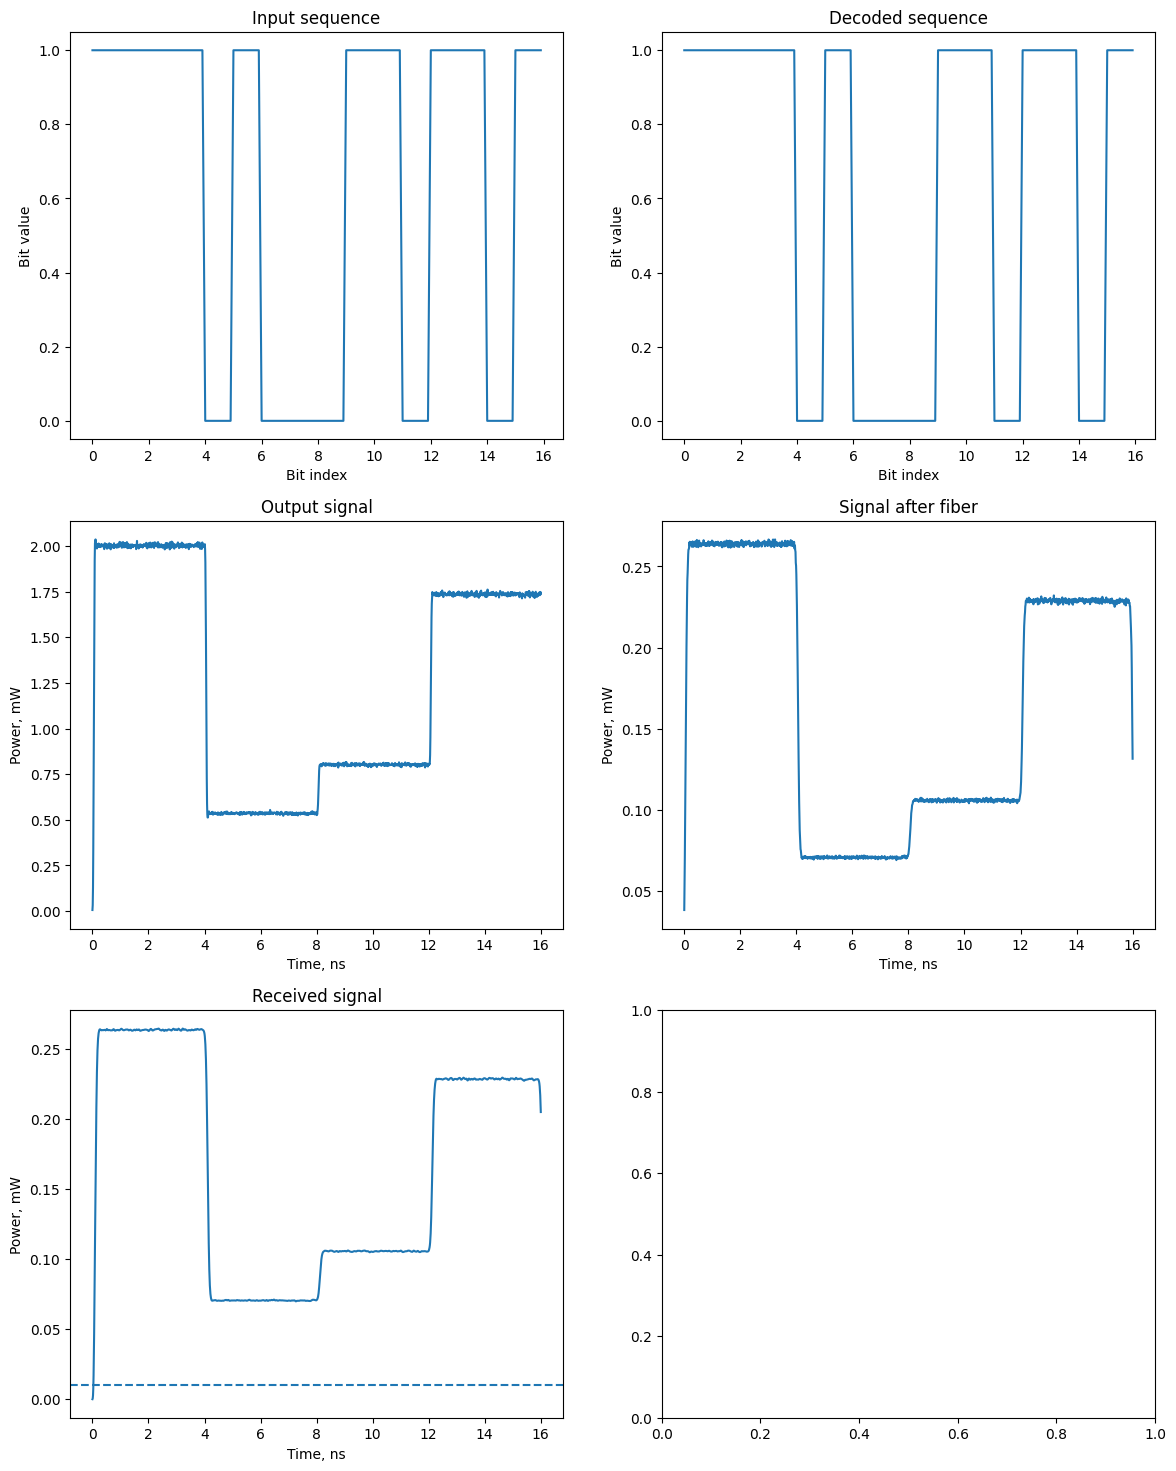

In [2]:
transmitter = System(components=[
    PAMEncoder(sampling_rate=100e9, data_rate=1e9, order=4),
    ElectricalLowPassFilter(order=5, cutoff_frequency=3e9),
    IntensityModulator(
        carrier_source=Transmitter(power=2e-3, linewidth=10e9, frequency_count=128)
    ),
    AWGN(level=-30.0)
])

channel = OpticalChannel(attenuation=0.22, length=40, chromatic_dispersion=17)

receiver = System(components=[
    Photodiode(),
    ElectricalLowPassFilter(order=5, cutoff_frequency=3e9)
])

decoder = PAMDecoder(data_rate=1e9, order=4)

system = System(components=[transmitter, channel, receiver])

input_signal = np.array([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype="bool")
output_signal = transmitter(input_signal)
fiber_signal = channel(output_signal)
received_signal = receiver(fiber_signal)
decoded_signal = decoder(received_signal)

ber = BERAnalyzer()(input_signal, decoded_signal)

fig, ((input_ax, decoded_ax), (output_ax, fiber_ax), (received_ax, _)) = plt.subplots(3, 2)
fig.set_size_inches(14, 18)

def w_to_dbm(w: np.ndarray) -> np.ndarray:
    return 10 * np.log10((w * 1000).clip(1e-30, 1e30))

input_ax.set_title("Input sequence")
output_ax.set_title("Output signal")
fiber_ax.set_title("Signal after fiber")
received_ax.set_title("Received signal")
decoded_ax.set_title("Decoded sequence")

input_ax.plot(np.arange(0, input_signal.size, 0.1), input_signal.repeat(10))
input_ax.set_xlabel("Bit index")
input_ax.set_ylabel("Bit value")

output_ax.plot(output_signal.timing.time * 1e9, np.sum(np.abs(output_signal.samples)**2 * 1000, axis=1))
output_ax.set_xlabel("Time, ns")
output_ax.set_ylabel("Power, mW")

fiber_ax.plot(fiber_signal.timing.time * 1e9, np.sum(np.abs(fiber_signal.samples)**2 * 1000, axis=1))
fiber_ax.set_xlabel("Time, ns")
fiber_ax.set_ylabel("Power, mW")

received_ax.plot(received_signal.timing.time * 1e9, received_signal.samples * 1000)
received_ax.axhline(decoder.threshold * 1000, linestyle="--")
received_ax.set_xlabel("Time, ns")
received_ax.set_ylabel("Power, mW")

decoded_ax.plot(np.arange(0, decoded_signal.size, 0.1), decoded_signal.repeat(10))
decoded_ax.set_xlabel("Bit index")
decoded_ax.set_ylabel("Bit value")

In [3]:
ber

0.0